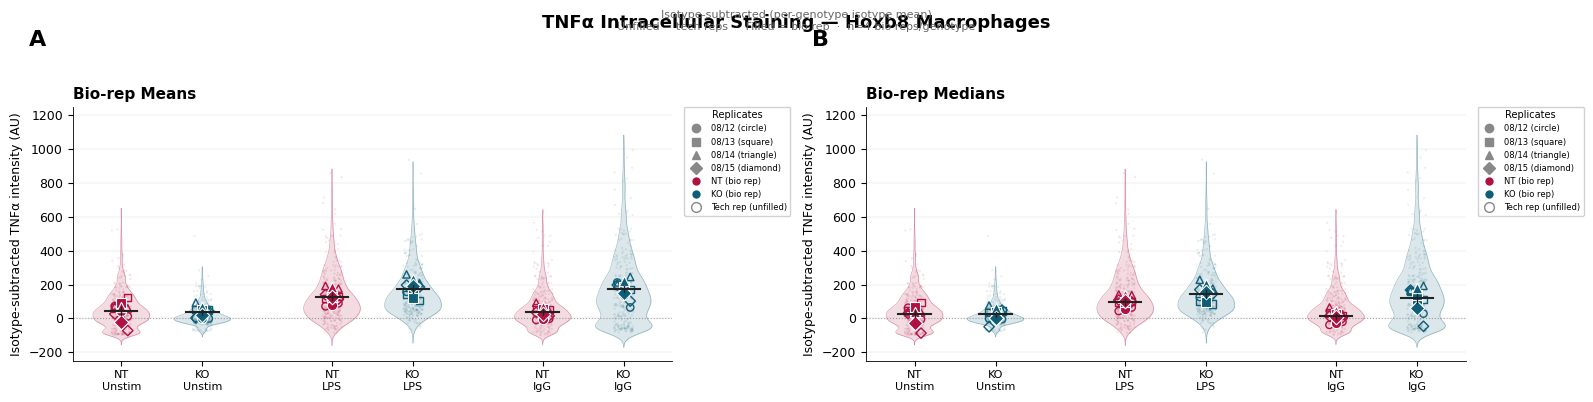

Saved: fig2_violins_isosub.pdf


In [1]:
# ═══════════════════════════════════════════════════════════════════════════
#  TNFα Intracellular Staining — Isotype-Subtracted Violin Superplots
#  Self-contained: run this cell alone.
# ═══════════════════════════════════════════════════════════════════════════

import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
import warnings
warnings.filterwarnings('ignore')

# ── Data ──────────────────────────────────────────────────────────────────
try:
    _dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _dir = os.getcwd()
df = pd.read_csv(os.path.join(_dir, 'tnfa_data_iso_subtracted.csv'))
dates = sorted(df['date'].unique())

# ── Isotype subtraction ──────────────────────────────────────────────────
# NT isotype mean = 504.98 AU (well F06, n=526)
# KO isotype mean = 485.21 AU (wells F02-F04, n=1669)
iso_mean = {'nt': 504.98, 'ko': 485.21}
df['iso_sub'] = df.apply(lambda r: r['mean_intensity_488'] - iso_mean[r['genotype']], axis=1)

# ── Style & layout constants ─────────────────────────────────────────────
geno_colors    = {'nt': '#B01141', 'ko': '#0F5E78'}
date_markers   = {20260812: 'o', 20260813: 's', 20260814: '^', 20260815: 'D'}
date_marker_labels = {20260812: '08/12 (circle)',   20260813: '08/13 (square)',
                      20260814: '08/14 (triangle)', 20260815: '08/15 (diamond)'}

group_order = [
    ('nt', 'blank'), ('ko', 'blank'),
    ('nt', 'lps'),   ('ko', 'lps'),
    ('nt', 'igg'),   ('ko', 'igg'),
]
group_label_map = {
    ('nt', 'blank'): 'NT\nUnstim', ('ko', 'blank'): 'KO\nUnstim',
    ('nt', 'lps'):   'NT\nLPS',    ('ko', 'lps'):   'KO\nLPS',
    ('nt', 'igg'):   'NT\nIgG',    ('ko', 'igg'):   'KO\nIgG',
}

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.size': 9,
    'axes.linewidth': 0.6,
})

x_positions = {}
x_ticks = []
x_ticklabels = []
xp = 0
for i, (geno, treat) in enumerate(group_order):
    x_positions[(geno, treat)] = xp
    x_ticks.append(xp)
    x_ticklabels.append(group_label_map[(geno, treat)])
    if i % 2 == 1 and i < len(group_order) - 1:
        xp += 1.6
    else:
        xp += 1.0

# ── Helper functions ─────────────────────────────────────────────────────
def compute_tech_rep_stat_iso(df, stat='mean'):
    records = []
    for geno, treat in group_order:
        for date in dates:
            sub = df[(df['genotype'] == geno) & (df['treatment'] == treat) & (df['date'] == date)]
            for tr in sorted(sub['tech_rep'].unique()):
                tr_sub = sub[sub['tech_rep'] == tr]['iso_sub']
                val = tr_sub.mean() if stat == 'mean' else tr_sub.median()
                records.append({'genotype': geno, 'treatment': treat, 'date': date,
                                'tech_rep': int(tr), 'value': val})
    return pd.DataFrame(records)


def compute_bio_rep_stat_iso(df, stat='mean'):
    tr_df = compute_tech_rep_stat_iso(df, stat)
    records = []
    for geno, treat in group_order:
        for date in dates:
            sub = tr_df[(tr_df['genotype'] == geno) & (tr_df['treatment'] == treat) & (tr_df['date'] == date)]
            if len(sub) == 0: continue
            records.append({'genotype': geno, 'treatment': treat, 'date': date,
                            'value': sub['value'].mean()})
    return pd.DataFrame(records)


def kde_violin(data, bw=0.15):
    data = data[np.isfinite(data)]
    if len(data) < 5: return None, None
    try:
        kde = gaussian_kde(data, bw_method=bw)
        top = np.percentile(data, 99.5)
        bottom = np.percentile(data, 0.5)
        pad = (top - bottom) * 0.08
        x_grid = np.linspace(bottom - pad, top, 200)
        return x_grid, kde(x_grid)
    except:
        return None, None


def plot_dots(ax, tr_data, br_data, group_keys, x_map):
    for date in dates:
        for geno, treat in group_keys:
            xc = x_map[(geno, treat)]
            color = geno_colors[geno]
            marker = date_markers[date]
            trs = tr_data[(tr_data['genotype'] == geno) & (tr_data['treatment'] == treat) &
                          (tr_data['date'] == date)]
            for _, row in trs.iterrows():
                offset = -0.08 if row['tech_rep'] == 1 else 0.08
                ax.scatter(xc + offset, row['value'], s=28, marker=marker,
                           facecolors='none', edgecolors=color,
                           linewidths=1.0, zorder=4)
    for date in dates:
        for geno, treat in group_keys:
            xc = x_map[(geno, treat)]
            marker = date_markers[date]
            row = br_data[(br_data['genotype'] == geno) & (br_data['treatment'] == treat) &
                          (br_data['date'] == date)]
            if len(row) > 0:
                ax.scatter(xc, row['value'].values[0], s=55, marker=marker,
                           color=geno_colors[geno], edgecolors='white',
                           linewidths=0.8, zorder=5)
    for geno, treat in group_keys:
        xc = x_map[(geno, treat)]
        vals = br_data[(br_data['genotype'] == geno) & (br_data['treatment'] == treat)]['value'].values
        if len(vals) > 0:
            m = np.mean(vals)
            sem = np.std(vals, ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0
            ax.plot([xc - 0.2, xc + 0.2], [m, m], color='#222', linewidth=1.5, zorder=6)
            ax.plot([xc, xc], [m - sem, m + sem], color='#222', linewidth=1.0, zorder=6)


def make_legend(ax, outside=False):
    handles = []
    for d in dates:
        handles.append(Line2D([0], [0], marker=date_markers[d], color='w',
                              markerfacecolor='#888', markeredgecolor='#888',
                              markersize=6, label=date_marker_labels[d]))
    handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='#B01141',
                          markersize=7, label='NT (bio rep)'))
    handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='#0F5E78',
                          markersize=7, label='KO (bio rep)'))
    handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='none',
                          markeredgecolor='#888', markersize=7, label='Tech rep (unfilled)'))
    if outside:
        ax.legend(handles=handles, fontsize=6, loc='upper left',
                  bbox_to_anchor=(1.02, 1), borderaxespad=0,
                  title='Replicates', title_fontsize=7, framealpha=0.9, edgecolor='#ccc')
    else:
        ax.legend(handles=handles, fontsize=6, loc='upper right',
                  title='Replicates', title_fontsize=7, framealpha=0.9, edgecolor='#ccc')

# ── Plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
fig.suptitle('TNFα Intracellular Staining — Hoxb8 Macrophages',
             fontsize=13, fontweight='bold', y=0.98)
fig.text(0.5, 0.94,
         'Isotype-subtracted (per-genotype isotype mean)\n'
         'Unfilled = tech reps  ·  Filled = bio rep  ·  '
         'n=4 bio reps/genotype',
         ha='center', fontsize=8, color='#666')

for panel_idx, (stat_name, br_data, tr_data) in enumerate([
    ('Mean',   compute_bio_rep_stat_iso(df, 'mean'),   compute_tech_rep_stat_iso(df, 'mean')),
    ('Median', compute_bio_rep_stat_iso(df, 'median'), compute_tech_rep_stat_iso(df, 'median')),
]):
    ax = axes[panel_idx]

    violin_width = 0.35
    for geno, treat in group_order:
        xc = x_positions[(geno, treat)]
        color = geno_colors[geno]
        cells = df[(df['genotype'] == geno) & (df['treatment'] == treat)]['iso_sub'].values
        y_grid, density = kde_violin(cells)
        if y_grid is not None:
            dn = density / density.max() * violin_width
            ax.fill_betweenx(y_grid, xc - dn, xc + dn, alpha=0.15,
                             color=color, linewidth=0)
            ax.plot(xc - dn, y_grid, color=color, linewidth=0.5, alpha=0.4)
            ax.plot(xc + dn, y_grid, color=color, linewidth=0.5, alpha=0.4)

    np.random.seed(42)
    for geno, treat in group_order:
        xc = x_positions[(geno, treat)]
        color = geno_colors[geno]
        cells = df[(df['genotype'] == geno) & (df['treatment'] == treat)]['iso_sub'].values
        cs = np.random.choice(cells, min(300, len(cells)), replace=False) if len(cells) > 0 else cells
        jitter = np.random.uniform(-0.12, 0.12, len(cs))
        ax.scatter(xc + jitter, cs, s=2.5, alpha=0.1, color=color,
                   edgecolors='none', zorder=1, rasterized=True)

    plot_dots(ax, tr_data, br_data, group_order, x_positions)

    ax.axhline(0, color='#999', ls=':', lw=0.8, zorder=0)
    ax.set_ylim(-250, 1250)
    ax.set_xlim(x_ticks[0] - 0.6, x_ticks[-1] + 0.6)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_ticklabels, fontsize=8)
    ax.set_ylabel('Isotype-subtracted TNFα intensity (AU)', fontsize=9)
    ax.set_title(f'Bio-rep {stat_name}s', fontsize=11, fontweight='600', loc='left')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linewidth=0.3, color='#ddd')
    make_legend(ax, outside=True)

fig.text(0.02, 0.90, 'A', fontsize=16, fontweight='bold')
fig.text(0.51, 0.90, 'B', fontsize=16, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig(os.path.join(_dir, 'fig2_violins_isosub.pdf'), dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig2_violins_isosub.pdf')